In [1]:
!pip -q install psycopg2-binary pgvector sentence-transformers huggingface_hub

import os
import numpy as np
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')
OUT = "/content/drive/MyDrive/filtered-vector-search"
os.makedirs(OUT, exist_ok=True)
print("Ready. Output folder:", OUT)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 60.2 MB/s eta 0:00:00
Mounted at /content/drive
Ready. Output folder: /content/drive/MyDrive/filtered-vector-search


In [2]:
from huggingface_hub import hf_hub_download

SAMPLE_PATH = f"{OUT}/arxiv_cs_50k.parquet"

if os.path.exists(SAMPLE_PATH):
    sample = pd.read_parquet(SAMPLE_PATH)
    print("Loaded saved sample:", sample.shape)
else:
    path = hf_hub_download(
        repo_id="librarian-bots/arxiv-metadata-snapshot",
        filename="data/train-00000-of-00011.parquet",
        repo_type="dataset",
        local_dir="/content/arxiv_raw",
    )
    df = pd.read_parquet(path)
    print("Loaded raw:", df.shape)

    mask = df["categories"].str.contains(r"(?:^| )cs\.", regex=True, na=False)
    cs = df[mask].drop_duplicates(subset=["id"]).copy()
    cs["primary_cat"] = cs["categories"].str.split().str[0]
    clean = lambda s: s.str.replace(r"\s+", " ", regex=True).str.strip()
    cs["text"] = clean(cs["title"]) + ". " + clean(cs["abstract"])
    cs["year"] = pd.to_datetime(cs["update_date"], errors="coerce").dt.year
    cs = cs.dropna(subset=["text", "year"])

    sample = cs.sample(n=min(50_000, len(cs)), random_state=42).reset_index(drop=True)
    rng = np.random.default_rng(42)
    sample["rand_attr"] = rng.integers(0, 1000, size=len(sample))
    sample.to_parquet(SAMPLE_PATH)
    print("Saved:", sample.shape)

print(sample["primary_cat"].value_counts().head(10))
print(sample["year"].describe())

Loaded saved sample: (50000, 18)
primary_cat
cs.LG      7421
cs.CV      6556
math.NA    5028
cs.CL      4127
cs.AI      4118
cs.RO      2772
eess.SY    2617
cs.CR      1766
cs.SE      1129
math.OC     981
Name: count, dtype: int64
count    50000.0
mean      2026.0
std          0.0
min       2026.0
25%       2026.0
50%       2026.0
75%       2026.0
max       2026.0
Name: year, dtype: float64


In [3]:
import torch
from sentence_transformers import SentenceTransformer

EMB_PATH = f"{OUT}/arxiv_emb.npy"
print("GPU availabel:", torch.cuda.is_available())

if os.path.exists(EMB_PATH):
  emb = np.load(EMB_PATH)
  print("Loaded saved embeddings:", emb.shape)
else:
  model = SentenceTransformer("all-MiniLM-L6-v2")
  emb = model.encode(sample["text"].tolist(), batch_size = 128,
                     show_progress_bar = True, normalize_embeddings = True)
  np.save(EMB_PATH, emb)
  print("saved:", emb.shape)

  assert len(emb) == len(sample), "Row count mismatch between sample and embeddings"

GPU availabel: True
Loaded saved embeddings: (50000, 384)


In [4]:
%%bash
sudo apt-get update -qq
sudo apt-get install -y -qq postgresql postgresql-contrib postgresql-server-dev-16 build-essential git
if [ ! -f /usr/share/postgresql/16/extension/vector.control ]; then
  cd /tmp && rm -rf pgvector
  git clone --branch v0.8.0 https://github.com/pgvector/pgvector.git
  cd pgvector
  make PG_CONFIG=/usr/lib/postgresql/16/bin/pg_config
  sudo make install PG_CONFIG=/usr/lib/postgresql/16/bin/pg_config
fi
sudo service postgresql restart
sudo -u postgres psql -c "ALTER USER postgres PASSWORD 'postgres';"
sudo -u postgres psql -c "DROP DATABASE IF EXISTS vsearch;"
sudo -u postgres psql -c "CREATE DATABASE vsearch;"
sudo -u postgres psql -d vsearch -c "CREATE EXTENSION vector;"
sudo -u postgres psql -d vsearch -c "\dx"

Selecting previously unselected package libjson-perl.
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack .../00-libjson-perl_4.10000-1_all.deb ...
Unpacking libjson-perl (4.10000-1) ...
Selecting previously unselected package postgresql-client-common.
Preparing to unpack .../01-postgresql-client-common_257build1.1_all.deb ...
Unpacking postgresql-client-common (257build1.1) ...
Selecting previously unselected package ssl-cert.
Preparing to unpack .../02-ssl-cert_1.1.2ubuntu1_all.deb ...
Unpacking ssl-cert (1.1.2ubuntu1) ...
Selecting previously unselected package postgresql-common.
Preparing to unpack .../03-postgresql-common_257build1.1_all.deb ...
Adding 'diversion of /usr/bin/pg_config to /usr/bin/pg_config.libpq-dev by postgresql-common'
Unpacking postgresql-common (257build1.1) ...
Selecting previously unselected package logrotate.
Preparing to unpack .../04-logrotate_3.21.0-2build1_amd64.deb ...
Unpacking logrotate (3.21.0-2build1) ...
Se

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 32.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Cloning into 'pgvector'...
Note: switching to '2627c5ff775ae6d7aef0c430121ccf857842d2f2'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain comm

In [5]:
%%bash
pg_lsclusters
ls /usr/lib/postgresql/
ls /usr/share/postgresql/16/extension | grep -i vector || echo "vector NOT installed"

Ver Cluster Port Status Owner    Data directory              Log file
16  main    5432 online postgres /var/lib/postgresql/16/main /var/log/postgresql/postgresql-16-main.log
16
vector--0.1.0--0.1.1.sql
vector--0.1.1--0.1.3.sql
vector--0.1.3--0.1.4.sql
vector--0.1.4--0.1.5.sql
vector--0.1.5--0.1.6.sql
vector--0.1.6--0.1.7.sql
vector--0.1.7--0.1.8.sql
vector--0.1.8--0.2.0.sql
vector--0.2.0--0.2.1.sql
vector--0.2.1--0.2.2.sql
vector--0.2.2--0.2.3.sql
vector--0.2.3--0.2.4.sql
vector--0.2.4--0.2.5.sql
vector--0.2.5--0.2.6.sql
vector--0.2.6--0.2.7.sql
vector--0.2.7--0.3.0.sql
vector--0.3.0--0.3.1.sql
vector--0.3.1--0.3.2.sql
vector--0.3.2--0.4.0.sql
vector--0.4.0--0.4.1.sql
vector--0.4.1--0.4.2.sql
vector--0.4.2--0.4.3.sql
vector--0.4.3--0.4.4.sql
vector--0.4.4--0.5.0.sql
vector--0.5.0--0.5.1.sql
vector--0.5.1--0.6.0.sql
vector--0.6.0--0.6.1.sql
vector--0.6.1--0.6.2.sql
vector--0.6.2--0.7.0.sql
vector--0.7.0--0.7.1.sql
vector--0.7.1--0.7.2.sql
vector--0.7.2--0.7.3.sql
vector--0.7.3--0.7.4.sq

In [6]:
%%bash
sudo apt-get update -qq
sudo apt-get install -y -qq postgresql-16-pgvector
ls /usr/share/postgresql/16/extension | grep -i vector || echo "vector NOT installed"

Selecting previously unselected package postgresql-16-pgvector.
(Reading database ... 134243 files and directories currently installed.)
Preparing to unpack .../postgresql-16-pgvector_0.6.0-1_amd64.deb ...
Unpacking postgresql-16-pgvector (0.6.0-1) ...
Setting up postgresql-16-pgvector (0.6.0-1) ...
Processing triggers for postgresql-common (257build1.1) ...
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
Building PostgreSQL dictionaries from installed myspell/hunspell packages...
Removing obsolete dictionary files:
vector--0.1.0--0.1.1.sql
vector--0.1.1--0.1.3.sql
vector--0.1.3--0.1.4.sql
vector--0.1.4--0.1.5.sql
vector--0.1.5--0.1.6.sql
vector--

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 


In [7]:
%%bash
sudo apt-get install -y -qq postgresql-server-dev-16 build-essential git
cd /tmp && rm -rf pgvector && git clone --branch v0.8.0 https://github.com/pgvector/pgvector.git
cd pgvector
make PG_CONFIG=/usr/lib/postgresql/16/bin/pg_config
sudo make install PG_CONFIG=/usr/lib/postgresql/16/bin/pg_config
ls /usr/share/postgresql/16/extension | grep -i vector || echo "vector NOT installed"

gcc -Wall -Wmissing-prototypes -Wpointer-arith -Wdeclaration-after-statement -Werror=vla -Wendif-labels -Wmissing-format-attribute -Wimplicit-fallthrough=3 -Wcast-function-type -Wshadow=compatible-local -Wformat-security -fno-strict-aliasing -fwrapv -fexcess-precision=standard -Wno-format-truncation -Wno-stringop-truncation -g -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -flto=auto -ffat-lto-objects -fstack-protector-strong -fstack-clash-protection -Wformat -Werror=format-security -fcf-protection -fno-omit-frame-pointer -march=native -ftree-vectorize -fassociative-math -fno-signed-zeros -fno-trapping-math -fPIC -fvisibility=hidden -I. -I./ -I/usr/include/postgresql/16/server -I/usr/include/postgresql/internal -Wdate-time -D_FORTIFY_SOURCE=3 -D_GNU_SOURCE  -I/usr/include/libxml2   -c -o src/bitutils.o src/bitutils.c
gcc -Wall -Wmissing-prototypes -Wpointer-arith -Wdeclaration-after-statement -Werror=vla -Wendif-labels -Wmissing-format-attribute -Wimplicit-fallthrough=3 -W

Cloning into 'pgvector'...
Note: switching to '2627c5ff775ae6d7aef0c430121ccf857842d2f2'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false



In [8]:
%%bash
sudo service postgresql restart
sudo -u postgres psql -c "ALTER USER postgres PASSWORD 'postgres';"
sudo -u postgres psql -c "CREATE DATABASE vsearch;" || true
sudo -u postgres psql -d vsearch -c "CREATE EXTENSION IF NOT EXISTS vector;"
sudo -u postgres psql -d vsearch -c "\dx"

 * Restarting PostgreSQL 16 database server
   ...done.
ALTER ROLE
CREATE EXTENSION
                             List of installed extensions
  Name   | Version |   Schema   |                     Description                      
---------+---------+------------+------------------------------------------------------
 plpgsql | 1.0     | pg_catalog | PL/pgSQL procedural language
 vector  | 0.8.0   | public     | vector data type and ivfflat and hnsw access methods
(2 rows)



ERROR:  database "vsearch" already exists
NOTICE:  extension "vector" already exists, skipping


In [9]:
import psycopg2
from psycopg2.extras import execute_values
from pgvector.psycopg2 import register_vector

conn = psycopg2.connect("dbname = vsearch user = postgres password = postgres host = localhost")
conn.autocommit = True
cur = conn.cursor()
cur.execute("CREATE EXTENSION IF NOT EXISTS vector")
register_vector(conn)

cur.execute("DROP TABLE IF EXISTS papers")
cur.execute("""
CREATE TABLE papers (
    id text PRIMARY KEY, title text, year int,
    primary_cat text, rand_attr int, embedding vector(384))
""")

rows = [(r.id, r.title, int(r.year), r.primary_cat, int(r.rand_attr), emb[i])
         for i, r in enumerate(sample.itertuples())]
execute_values(cur,
               "INSERT INTO papers (id,title,year,primary_cat,rand_attr,embedding) VALUES %s",
               rows, page_size = 1000)

cur.execute("CREATE INDEX ON papers (rand_attr)")
cur.execute("CREATE INDEX ON papers (year)")
cur.execute("CREATE INDEX ON papers (primary_cat)")
cur.execute("ANALYZE papers")

cur.execute("SELECT count(*) FROM papers");
print(cur.fetchone())

cur.execute("SELECT count(*) FROM papers WHERE rand_attr<10");
print(cur.fetchone())

(50000,)
(515,)


In [10]:
import time

# index check: there must be NO hnsw index yet
cur.execute("SELECT indexname FROM pg_indexes WHERE tablename = 'papers'")
print(cur.fetchall())

N_Q = 200
rng = np.random.default_rng(123)
q_idx = rng.choice(len(sample), size = N_Q, replace = False)      # papers used as quries
SEL = {0.1: 1, 0.5: 5, 1: 10, 5: 50, 10: 100, 25: 250, 50: 500}   # selectivity % -> rand_attr < k

SQL_FILTERED = """SELECT id FROM papers
                  WHERE rand_attr < %s AND id <> %s
                  ORDER BY embedding <=> %s LIMIT 10"""
# "id <> '%s' removes the query paper itself, so it can't match itself"

def timed(sql, params):
  t0 = time.perf_counter()
  cur.execute(sql, params)
  ids = [r[0] for r in cur.fetchall()]
  return ids, (time.perf_counter() - t0) * 100    # milliseconds

# warm-up so the first timings aren't inflated by a cold cache
for i in q_idx[:20]:
  timed(SQL_FILTERED, (500, sample.at[i, "id"], emb[i]))

truth, exact_ms = {}, {}
for s, k in SEL.items():
  for i in q_idx:
    ids, ms = timed(SQL_FILTERED, (k, sample.at[i, "id"], emb[i]))
    truth[(s, int(i))] = ids
    exact_ms[(s, int(i))] = ms
  print(f"{s}% done")




[('papers_pkey',), ('papers_rand_attr_idx',), ('papers_year_idx',), ('papers_primary_cat_idx',)]
0.1% done
0.5% done
1% done
5% done
10% done
25% done
50% done


In [11]:
# Building the HNSW index

cur.execute("DROP INDEX IF EXISTS papers_hnsw")
t0 = time.time()
cur.execute("""CREATE INDEX papers_hnsw ON papers
               USING hnsw (embedding vector_cosine_ops)
               WITH (m = 16, ef_construction = 64)""")
cur.execute("ANALYZE papers")
print("HNSW built in", round(time.time() - t0, 1), "s")

HNSW built in 44.4 s


In [12]:
SQL_OVERFETCH = """SELECT id FROM (
                     SELECT id, rand_attr, embedding <=> %s AS d FROM papers
                     WHERE id <> %s ORDER BY embedding <=> %s LIMIT %s) t
                   WHERE rand_attr < %s ORDER BY d LIMIT 10"""
C = 100   # candidates fetched by the over-fetch strategy

def recall(ids, gt):
    return len(set(ids) & set(gt)) / max(len(gt), 1)

results = []
# strategy 1: exact pre-filter (stored from Cell 6)
for (s, i), ms in exact_ms.items():
    results.append(dict(strategy="1_exact_prefilter", sel=s, recall=1.0, ms=ms))

def run_strategy(name, settings, make_query):
    for stmt in settings:
        cur.execute(stmt)
    for s, k in SEL.items():
        for i in q_idx:
            i = int(i)
            ids, ms = timed(*make_query(k, i))
            results.append(dict(strategy=name, sel=s, recall=recall(ids, truth[(s, i)]), ms=ms))
    print(name, "done")

where_q = lambda k, i: (SQL_FILTERED, (k, sample.at[i, "id"], emb[i]))
over_q  = lambda k, i: (SQL_OVERFETCH, (emb[i], sample.at[i, "id"], emb[i], C, k))

run_strategy("2_hnsw_where",
             ["SET hnsw.ef_search = 40", "SET hnsw.iterative_scan = off"], where_q)
run_strategy("3_hnsw_overfetch100",
             ["SET hnsw.ef_search = 100", "SET hnsw.iterative_scan = off"], over_q)
run_strategy("4_hnsw_iterative",
             ["SET hnsw.ef_search = 40", "SET hnsw.iterative_scan = relaxed_order"], where_q)

cur.execute("SET hnsw.iterative_scan = off")   # reset

res = pd.DataFrame(results)
summary = (res.groupby(["strategy", "sel"])
              .agg(recall=("recall", "mean"),
                   p50_ms=("ms", "median"),
                   p95_ms=("ms", lambda x: x.quantile(0.95)))
              .round(3).reset_index())
print(summary.to_string(index=False))
res.to_csv(f"{OUT}/results_arxiv.csv", index=False)

2_hnsw_where done
3_hnsw_overfetch100 done
4_hnsw_iterative done
           strategy  sel  recall  p50_ms  p95_ms
  1_exact_prefilter  0.1   1.000   0.084   0.096
  1_exact_prefilter  0.5   1.000   0.108   0.149
  1_exact_prefilter  1.0   1.000   0.136   0.157
  1_exact_prefilter  5.0   1.000   0.341   0.450
  1_exact_prefilter 10.0   1.000   0.602   0.763
  1_exact_prefilter 25.0   1.000   2.015   2.368
  1_exact_prefilter 50.0   1.000   2.521   2.905
       2_hnsw_where  0.1   1.000   0.087   0.099
       2_hnsw_where  0.5   1.000   0.107   0.127
       2_hnsw_where  1.0   1.000   0.134   0.185
       2_hnsw_where  5.0   0.204   0.153   0.185
       2_hnsw_where 10.0   0.390   0.149   0.175
       2_hnsw_where 25.0   0.868   0.151   0.177
       2_hnsw_where 50.0   0.990   0.141   0.186
3_hnsw_overfetch100  0.1   0.012   0.274   0.391
3_hnsw_overfetch100  0.5   0.061   0.265   0.326
3_hnsw_overfetch100  1.0   0.114   0.265   0.304
3_hnsw_overfetch100  5.0   0.527   0.267   0.324
3_hn

In [13]:
# Which plan did postgres actually use?

cur.execute("SET hnsw.iterative_scan = off")
i0 = int(q_idx[0])
for s, k in SEL.items():
  cur.execute("EXPLAIN " + SQL_FILTERED, (k, sample.at[i0, "id"], emb[i0]))
  txt = " ".join(r[0] for r in cur.fetchall())
  plan = "HNSW" if "papers_hnsw" in txt else ("btree on rand_attr" if "rand_attr" in txt else "seq scan")
  print(f"{s:>5}% -> {plan}")

  0.1% -> btree on rand_attr
  0.5% -> btree on rand_attr
    1% -> btree on rand_attr
    5% -> HNSW
   10% -> HNSW
   25% -> HNSW
   50% -> HNSW


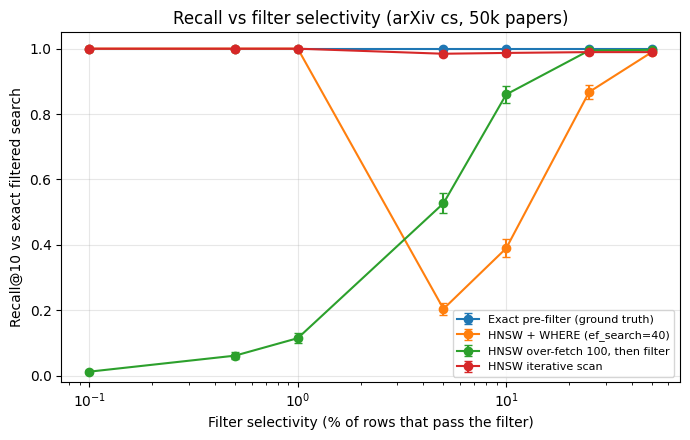

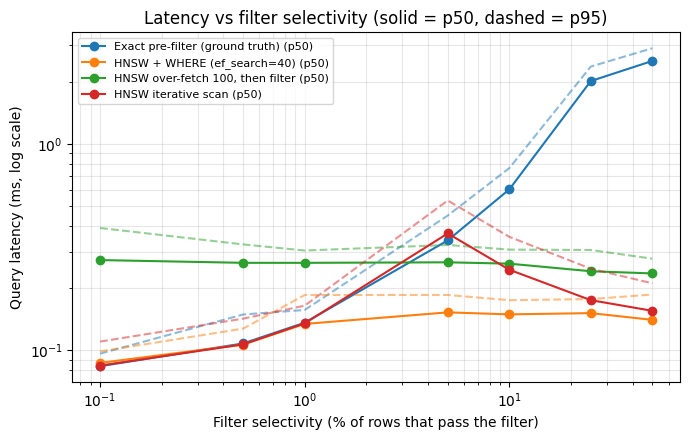

In [14]:
import matplotlib.pyplot as plt

FIG = f"{OUT}/figures"
os.makedirs(FIG, exist_ok=True)

NAMES = {
    "1_exact_prefilter":   "Exact pre-filter (ground truth)",
    "2_hnsw_where":        "HNSW + WHERE (ef_search=40)",
    "3_hnsw_overfetch100": "HNSW over-fetch 100, then filter",
    "4_hnsw_iterative":    "HNSW iterative scan",
}

# mean recall with a 95% confidence interval across the 200 queries
g = res.groupby(["strategy", "sel"])
stats = g.agg(recall=("recall", "mean"),
              rec_se=("recall", lambda x: x.std(ddof=1) / np.sqrt(len(x))),
              p50=("ms", "median"),
              p95=("ms", lambda x: x.quantile(0.95))).reset_index()

# ---- Plot 1: recall@10 vs selectivity ----
fig, ax = plt.subplots(figsize=(7, 4.5))
for s, d in stats.groupby("strategy"):
    d = d.sort_values("sel")
    ax.errorbar(d["sel"], d["recall"], yerr=1.96 * d["rec_se"],
                marker="o", capsize=3, label=NAMES[s])
ax.set_xscale("log")
ax.set_xlabel("Filter selectivity (% of rows that pass the filter)")
ax.set_ylabel("Recall@10 vs exact filtered search")
ax.set_title("Recall vs filter selectivity (arXiv cs, 50k papers)")
ax.set_ylim(-0.02, 1.05)
ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{FIG}/recall_vs_selectivity.png", dpi=200)
plt.show()

# ---- Plot 2: latency vs selectivity ----
fig, ax = plt.subplots(figsize=(7, 4.5))
for s, d in stats.groupby("strategy"):
    d = d.sort_values("sel")
    line, = ax.plot(d["sel"], d["p50"], marker="o", label=NAMES[s] + " (p50)")
    ax.plot(d["sel"], d["p95"], linestyle="--", alpha=0.5, color=line.get_color())
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Filter selectivity (% of rows that pass the filter)")
ax.set_ylabel("Query latency (ms, log scale)")
ax.set_title("Latency vs filter selectivity (solid = p50, dashed = p95)")
ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{FIG}/latency_vs_selectivity.png", dpi=200)
plt.show()

In [15]:
# README table and error analysis

# ---recall and p50 latency side by side ---
tbl = stats.assign(cell = lambda d: d["recall"].round(3).astype(str)
                   + "/" +d["p50"].round(2).astype(str) + " ms")
table = tbl.pivot(index = "sel", columns = "strategy", values = "cell")
table.columns = [NAMES[c] for c in table.columns]
print(table.to_string())
table.to_csv(f"{OUT}/summary_table.csv")

# ---- Error analysis : how often does each strategy fail completely? ----
rows = []
for (s, sel), d in res.groupby(["strategy", "sel"]):
  rows.append(dict(strategy = NAMES[s], sel = sel,
                   recall_zero = (d["recall"] == 0).mean(),
                   recall_below_half = (d["recall"] < 0.5).mean(),
                   mean_recall = d["recall"].mean()))
err = pd.DataFrame(rows)
print(err[err["sel"].isin([0.1, 1, 10])].round(3).to_string(index = False))

     Exact pre-filter (ground truth) HNSW + WHERE (ef_search=40) HNSW over-fetch 100, then filter HNSW iterative scan
sel                                                                                                                  
0.1                      1.0/0.08 ms                 1.0/0.09 ms                    0.012/0.27 ms         1.0/0.08 ms
0.5                      1.0/0.11 ms                 1.0/0.11 ms                    0.061/0.27 ms         1.0/0.11 ms
1.0                      1.0/0.14 ms                 1.0/0.13 ms                    0.114/0.27 ms         1.0/0.14 ms
5.0                      1.0/0.34 ms               0.204/0.15 ms                    0.527/0.27 ms       0.984/0.37 ms
10.0                      1.0/0.6 ms                0.39/0.15 ms                     0.86/0.26 ms       0.987/0.25 ms
25.0                     1.0/2.01 ms               0.868/0.15 ms                    0.994/0.24 ms        0.99/0.18 ms
50.0                     1.0/2.52 ms                0.99

In [18]:
import json, time

TARGET = 0.95            # minimum acceptable mean recall@10
N = len(sample)

# ---- 1. Calibrate the lookup policy from the Cell 8 results ----
policy = {}
for sel, d in stats.groupby("sel"):
    ok = d[d["recall"] >= TARGET].sort_values("p50")   # cheapest strategy that meets the target
    policy[sel] = ok.iloc[0]["strategy"]               # exact pre-filter always qualifies (recall = 1)
print("Policy (selectivity % -> strategy):")
for s in sorted(policy): print(f"  {s:>5}% -> {policy[s]}")

cal_sels = np.array(sorted(policy))
def route(est_pct):
    # nearest calibrated selectivity in log space
    j = np.argmin(np.abs(np.log(cal_sels) - np.log(max(est_pct, 1e-3))))
    return policy[cal_sels[j]]

# ---- 2. Selectivity estimator from the planner (no data scan) ----
def est_sel(k):
    cur.execute("EXPLAIN (FORMAT JSON) SELECT 1 FROM papers WHERE rand_attr < %s", (k,))
    plan = cur.fetchone()[0]
    if isinstance(plan, str): plan = json.loads(plan)
    return plan[0]["Plan"]["Plan Rows"] / N * 100

# ---- 3. One function that runs any strategy ----
C = 100
def run_one(strategy, k, i):
    sid, q = sample.at[i, "id"], emb[i]
    if strategy == "1_exact_prefilter":
        cur.execute("SET enable_indexscan = off")          # forces an exact scan
        sql, params = SQL_FILTERED, (k, sid, q)
    elif strategy == "2_hnsw_where":
        cur.execute("SET hnsw.ef_search = 40"); cur.execute("SET hnsw.iterative_scan = off")
        sql, params = SQL_FILTERED, (k, sid, q)
    elif strategy == "3_hnsw_overfetch100":
        cur.execute("SET hnsw.ef_search = 100"); cur.execute("SET hnsw.iterative_scan = off")
        sql, params = SQL_OVERFETCH, (q, sid, q, C, k)
    elif strategy == "4_hnsw_iterative":
        cur.execute("SET hnsw.ef_search = 40"); cur.execute("SET hnsw.iterative_scan = relaxed_order")
        sql, params = SQL_FILTERED, (k, sid, q)
    ids, ms = timed(sql, params)
    cur.execute("RESET enable_indexscan"); cur.execute("SET hnsw.iterative_scan = off")
    return ids, ms

# ---- 4. Held-out test: NEW queries and OFF-GRID selectivities ----
rng2 = np.random.default_rng(456)
pool = np.setdiff1d(np.arange(N), q_idx)
test_idx = rng2.choice(pool, size=200, replace=False)
TEST_K = [2, 8, 20, 75, 150, 350]                  # 0.2%, 0.8%, 2%, 7.5%, 15%, 35%

for i in test_idx[:20]:                            # warm-up
    run_one("1_exact_prefilter", 500, int(i))

STRATS = ["1_exact_prefilter", "2_hnsw_where", "3_hnsw_overfetch100", "4_hnsw_iterative"]
rows = []
for k in TEST_K:
    for i in test_idx:
        i = int(i)
        gt, _ = run_one("1_exact_prefilter", k, i)        # ground truth for this query
        for s in STRATS:
            ids, ms = run_one(s, k, i)
            rows.append(dict(strategy=s, k=k, sel=k / 10, qi=i,
                             recall=len(set(ids) & set(gt)) / max(len(gt), 1), ms=ms))
    print(f"k={k} done")

test_res = pd.DataFrame(rows)
test_res.to_csv(f"{OUT}/test_results_arxiv.csv", index=False)
print(test_res.shape)

Policy (selectivity % -> strategy):
    0.1% -> 1_exact_prefilter
    0.5% -> 2_hnsw_where
    1.0% -> 2_hnsw_where
    5.0% -> 1_exact_prefilter
   10.0% -> 4_hnsw_iterative
   25.0% -> 4_hnsw_iterative
   50.0% -> 2_hnsw_where
k=2 done
k=8 done
k=20 done
k=75 done
k=150 done
k=350 done
(4800, 6)


  k  true_sel_pct  est_sel_pct            chosen
  2           0.2         0.14 1_exact_prefilter
  8           0.8         0.84      2_hnsw_where
 20           2.0         1.93      2_hnsw_where
 75           7.5         7.60  4_hnsw_iterative
150          15.0        15.15  4_hnsw_iterative
350          35.0        35.14  4_hnsw_iterative
                     mean_recall  frac_recall_ok  p50_ms  p95_ms
strategy                                                        
1_exact_prefilter          1.000           1.000   0.731   2.980
2_hnsw_where               0.660           0.489   0.218   0.542
3_hnsw_overfetch100        0.500           0.327   0.401   1.029
4_hnsw_iterative           0.988           0.906   0.209   1.402
R_router                   0.836           0.758   0.620   1.058


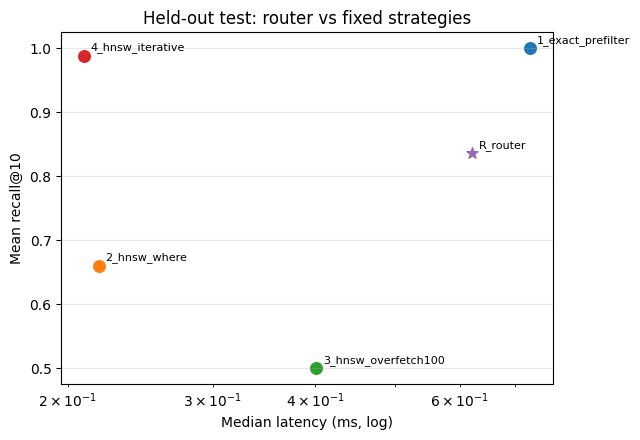

In [19]:
# router = for each filter, estimate selectivity, pick a strategy, use its measured results
router_rows, est_table = [], []
for k in TEST_K:
    t0 = time.perf_counter()
    est = est_sel(k)
    est_ms = (time.perf_counter() - t0) * 1000
    chosen = route(est)
    est_table.append(dict(k=k, true_sel_pct=k / 10, est_sel_pct=round(est, 2), chosen=chosen))
    d = test_res[(test_res["k"] == k) & (test_res["strategy"] == chosen)].copy()
    d["strategy"] = "R_router"
    d["ms"] = d["ms"] + est_ms        # every query pays the estimation cost (conservative)
    router_rows.append(d)

print(pd.DataFrame(est_table).to_string(index=False))

all_res = pd.concat([test_res, *router_rows])
summary2 = (all_res.groupby("strategy")
            .agg(mean_recall=("recall", "mean"),
                 frac_recall_ok=("recall", lambda x: (x >= TARGET).mean()),
                 p50_ms=("ms", "median"),
                 p95_ms=("ms", lambda x: x.quantile(0.95)))
            .round(3))
print(summary2)
summary2.to_csv(f"{OUT}/router_summary.csv")

# trade-off plot: recall vs latency, one point per strategy
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for s, r in summary2.iterrows():
    ax.scatter(r["p50_ms"], r["mean_recall"], s=70, marker="*" if s == "R_router" else "o")
    ax.annotate(s, (r["p50_ms"], r["mean_recall"]), fontsize=8, xytext=(5, 4), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("Median latency (ms, log)"); ax.set_ylabel("Mean recall@10")
ax.set_title("Held-out test: router vs fixed strategies"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG}/router_tradeoff.png", dpi=200); plt.show()

In [20]:
import json

# --- categories spanning big to small ---
vc = sample["primary_cat"].value_counts()
ranks = [r for r in [0, 2, 5, 10, 20, 40] if r < len(vc)]
cats = vc.index[ranks].tolist()
print((vc / len(sample) * 100).round(2)[cats])

# --- queries: "matched" = from inside the category, "mismatched" = from outside ---
rng3 = np.random.default_rng(789)
def pick(cat, inside, n=50):
    m = (sample["primary_cat"] == cat).to_numpy()
    pool = np.where(m)[0] if inside else np.where(~m)[0]
    return rng3.choice(pool, size=min(n, len(pool)), replace=False)

SQL_CAT = """SELECT id FROM papers
             WHERE primary_cat = %s AND id <> %s
             ORDER BY embedding <=> %s LIMIT 10"""
SQL_CAT_OVER = """SELECT id FROM (
                    SELECT id, primary_cat, embedding <=> %s AS d FROM papers
                    WHERE id <> %s ORDER BY embedding <=> %s LIMIT %s) t
                  WHERE primary_cat = %s ORDER BY d LIMIT 10"""

def run_cat(strategy, cat, i):
    sid, q = sample.at[i, "id"], emb[i]
    cur.execute("SET hnsw.iterative_scan = off")
    if strategy == "1_exact_prefilter":
        cur.execute("SET enable_indexscan = off")
        sql, params = SQL_CAT, (cat, sid, q)
    elif strategy == "2_hnsw_where":
        cur.execute("SET hnsw.ef_search = 40")
        sql, params = SQL_CAT, (cat, sid, q)
    elif strategy == "3_hnsw_overfetch100":
        cur.execute("SET hnsw.ef_search = 100")
        sql, params = SQL_CAT_OVER, (q, sid, q, 100, cat)
    elif strategy == "4_hnsw_iterative":
        cur.execute("SET hnsw.ef_search = 40")
        cur.execute("SET hnsw.iterative_scan = relaxed_order")
        sql, params = SQL_CAT, (cat, sid, q)
    ids, ms = timed(sql, params)
    cur.execute("RESET enable_indexscan"); cur.execute("SET hnsw.iterative_scan = off")
    return ids, ms

rows = []
for cat in cats:
    for cond, inside in [("matched", True), ("mismatched", False)]:
        for i in pick(cat, inside):
            i = int(i)
            gt, _ = run_cat("1_exact_prefilter", cat, i)
            for s in STRATS:
                ids, ms = run_cat(s, cat, i)
                rows.append(dict(strategy=s, cat=cat, sel=round(vc[cat] / len(sample) * 100, 2),
                                 cond=cond, recall=len(set(ids) & set(gt)) / max(len(gt), 1), ms=ms))
    print(cat, "done")

cat_res = pd.DataFrame(rows)
cat_res.to_csv(f"{OUT}/category_results_arxiv.csv", index=False)

pt = (cat_res.groupby(["sel", "cond", "strategy"])["recall"].mean().round(3)
             .unstack("strategy"))
pt.columns = [NAMES[c] for c in pt.columns]
print(pt.to_string())

primary_cat
cs.LG      14.84
math.NA    10.06
cs.RO       5.54
cs.HC       1.85
cs.GT       0.75
cs.CG       0.21
Name: count, dtype: float64
cs.LG done
math.NA done
cs.RO done
cs.HC done
cs.GT done
cs.CG done
                  Exact pre-filter (ground truth)  HNSW + WHERE (ef_search=40)  HNSW over-fetch 100, then filter  HNSW iterative scan
sel   cond                                                                                                                           
0.21  matched                                 1.0                        1.000                             0.758                1.000
      mismatched                              1.0                        1.000                             0.024                1.000
0.75  matched                                 1.0                        1.000                             0.926                1.000
      mismatched                              1.0                        1.000                             0.036        

In [21]:
def est_sel_cat(cat):
    cur.execute("EXPLAIN (FORMAT JSON) SELECT 1 FROM papers WHERE primary_cat = %s", (cat,))
    plan = cur.fetchone()[0]
    if isinstance(plan, str): plan = json.loads(plan)
    return plan[0]["Plan"]["Plan Rows"] / len(sample) * 100

out = []
for cat in cats:
    chosen = route(est_sel_cat(cat))
    d = cat_res[(cat_res["cat"] == cat) & (cat_res["strategy"] == chosen)]
    best_fixed = cat_res[cat_res["cat"] == cat].groupby("strategy")["recall"].mean().max()
    for cond in ["matched", "mismatched"]:
        out.append(dict(cat=cat, true_sel=round(vc[cat] / len(sample) * 100, 2),
                        chosen=chosen, cond=cond,
                        router_recall=round(d[d["cond"] == cond]["recall"].mean(), 3)))
print(pd.DataFrame(out).to_string(index=False))

    cat  true_sel            chosen       cond  router_recall
  cs.LG     14.84  4_hnsw_iterative    matched          0.984
  cs.LG     14.84  4_hnsw_iterative mismatched          0.956
math.NA     10.06  4_hnsw_iterative    matched          0.998
math.NA     10.06  4_hnsw_iterative mismatched          0.820
  cs.RO      5.54 1_exact_prefilter    matched          1.000
  cs.RO      5.54 1_exact_prefilter mismatched          1.000
  cs.HC      1.85      2_hnsw_where    matched          0.792
  cs.HC      1.85      2_hnsw_where mismatched          0.012
  cs.GT      0.75      2_hnsw_where    matched          1.000
  cs.GT      0.75      2_hnsw_where mismatched          1.000
  cs.CG      0.21      2_hnsw_where    matched          1.000
  cs.CG      0.21      2_hnsw_where mismatched          1.000


In [22]:
from importlib.metadata import version
cur.execute("SELECT extversion FROM pg_extension WHERE extname='vector'"); pgv = cur.fetchone()[0]
cur.execute("SHOW server_version"); pg = cur.fetchone()[0]

meta = dict(
    dataset="librarian-bots/arxiv-metadata-snapshot, shard train-00000-of-00011",
    rows=len(sample), sample_seed=42, embedding_model="all-MiniLM-L6-v2", dim=384,
    postgres=pg, pgvector=pgv,
    hnsw=dict(m=16, ef_construction=64),
    ef_search=dict(where=40, overfetch=100, iterative=40), overfetch_candidates=100,
    n_queries_calibration=200, n_queries_test=200, recall_target=0.95,
    python_libs={p: version(p) for p in ["pandas", "numpy", "psycopg2-binary", "pgvector", "sentence-transformers"]},
    download_date="<fill in the date you downloaded the shard>",
)
json.dump(meta, open(f"{OUT}/run_metadata.json", "w"), indent=2)
print(json.dumps(meta, indent=2))

{
  "dataset": "librarian-bots/arxiv-metadata-snapshot, shard train-00000-of-00011",
  "rows": 50000,
  "sample_seed": 42,
  "embedding_model": "all-MiniLM-L6-v2",
  "dim": 384,
  "postgres": "16.15 (Ubuntu 16.15-0ubuntu0.24.04.1)",
  "pgvector": "0.8.0",
  "hnsw": {
    "m": 16,
    "ef_construction": 64
  },
  "ef_search": {
    "where": 40,
    "overfetch": 100,
    "iterative": 40
  },
  "overfetch_candidates": 100,
  "n_queries_calibration": 200,
  "n_queries_test": 200,
  "recall_target": 0.95,
  "python_libs": {
    "pandas": "2.2.3",
    "numpy": "2.1.3",
    "psycopg2-binary": "2.9.13",
    "pgvector": "0.5.1",
    "sentence-transformers": "5.7.0"
  },
  "download_date": "<fill in the date you downloaded the shard>"
}


In [23]:
import shutil
os.makedirs(f"{OUT}/results", exist_ok=True)
for f in ["results_arxiv.csv", "test_results_arxiv.csv", "category_results_arxiv.csv",
          "router_summary.csv", "summary_table.csv", "run_metadata.json"]:
    if os.path.exists(f"{OUT}/{f}"):
        shutil.copy(f"{OUT}/{f}", f"{OUT}/results/{f}")
shutil.copytree(f"{OUT}/figures", f"{OUT}/results/figures", dirs_exist_ok=True)
shutil.make_archive("/content/results_bundle", "zip", f"{OUT}/results")
print(os.listdir(f"{OUT}/results"))

['results_arxiv.csv', 'test_results_arxiv.csv', 'category_results_arxiv.csv', 'router_summary.csv', 'summary_table.csv', 'run_metadata.json', 'figures']


In [24]:
from importlib.metadata import version
for p in ["pandas","numpy","psycopg2-binary","pgvector","sentence-transformers","matplotlib","huggingface_hub","pyarrow"]:
    print(f"{p}=={version(p)}")

pandas==2.2.3
numpy==2.1.3
psycopg2-binary==2.9.13
pgvector==0.5.1
sentence-transformers==5.7.0
matplotlib==3.10.0
huggingface_hub==1.33.0
pyarrow==23.0.1
